# Spotify Music Analysis

This notebook explores the Spotify tracks dataset, checks its initial data quality, and compares popularity and audio-feature averages across genres. The analysis is exploratory: observations describe this dataset and do not establish causes.

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Spotify Music Analysis")

Spotify Music Analysis


In [15]:
df = pd.read_csv("../data/dataset.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


## 1. Dataset overview and initial quality checks

Start by loading the CSV and inspecting its dimensions, columns, missing values, duplicate rows, and the `Unnamed: 0` field.

In [16]:
df.head()

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [17]:
df.shape

(114000, 21)

In [18]:
df.columns.tolist()

['Unnamed: 0',
 'track_id',
 'artists',
 'album_name',
 'track_name',
 'popularity',
 'duration_ms',
 'explicit',
 'danceability',
 'energy',
 'key',
 'loudness',
 'mode',
 'speechiness',
 'acousticness',
 'instrumentalness',
 'liveness',
 'valence',
 'tempo',
 'time_signature',
 'track_genre']

In [19]:
df.isnull().sum()

Unnamed: 0          0
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64

In [20]:
df.duplicated().sum()

np.int64(0)

In [21]:
df.columns

Index(['Unnamed: 0', 'track_id', 'artists', 'album_name', 'track_name',
       'popularity', 'duration_ms', 'explicit', 'danceability', 'energy',
       'key', 'loudness', 'mode', 'speechiness', 'acousticness',
       'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature',
       'track_genre'],
      dtype='str')

In [22]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  str    
 2   artists           113999 non-null  str    
 3   album_name        113999 non-null  str    
 4   track_name        113999 non-null  str    
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          114000 non-nu

In [23]:
df[df.isnull().any(axis=1)]

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
65900,65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,0,0,False,0.501,0.583,...,-9.46,0,0.0605,0.69,0.00396,0.0747,0.734,138.391,4,k-pop


In [24]:
df.duplicated().sum()

np.int64(0)

In [25]:
df["Unnamed: 0"].head()

0    0
1    1
2    2
3    3
4    4
Name: Unnamed: 0, dtype: int64

In [26]:
df["Unnamed: 0"].nunique()

114000

In [27]:
df.duplicated().sum()

np.int64(0)

### Initial inspection findings

The dataset has 114,000 rows and 21 columns, with 1,000 tracks per genre. There is one missing value in each of `artists`, `album_name`, and `track_name`; all three belong to the same row. No exact duplicate rows were found. `Unnamed: 0` contains 114,000 unique values and may be a redundant original index. These are initial checks only: no complete cleaning has been performed, and the missing values and index column have not yet been handled.

## 2. Popularity distribution

The summary below reports a mean of about 33.24, a median of 35, a standard deviation of about 22.31, and a range from 0 to 100. The histogram shows how scores are distributed; it describes the data but does not explain what causes a track to receive a particular score.

In [28]:
df["popularity"].describe()

count    114000.000000
mean         33.238535
std          22.305078
min           0.000000
25%          17.000000
50%          35.000000
75%          50.000000
max         100.000000
Name: popularity, dtype: float64

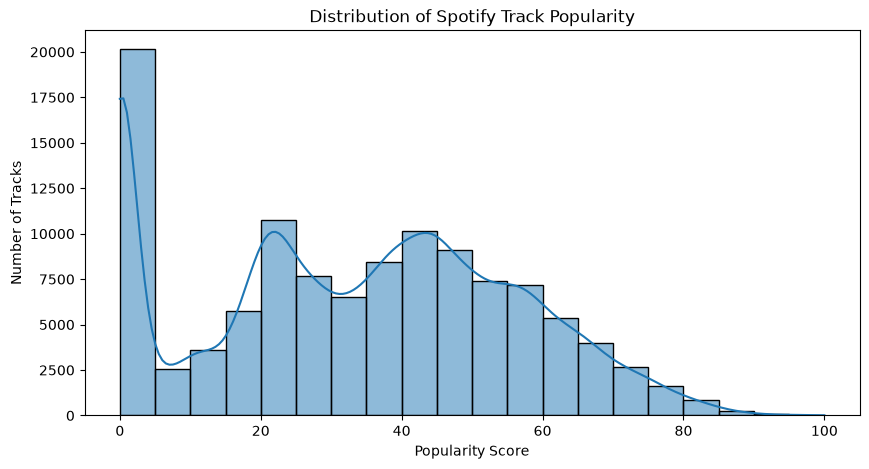

In [29]:
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x="popularity", bins=20, kde=True)

plt.title("Distribution of Spotify Track Popularity")
plt.xlabel("Popularity Score")
plt.ylabel("Number of Tracks")

plt.show()

In [30]:
df["Unnamed: 0"].nunique()

114000

In [31]:
df.duplicated().sum()

np.int64(0)

### Tracks with zero popularity

There are 16,020 tracks with a popularity score of zero (14.05% of the dataset). The largest genre percentages are Jazz (68.1%), Iranian (65.6%), and Romance (63.6%). The following cells calculate the count and show the genre-level results.

**Limitation:** a zero score does not establish that a track has never been listened to, and these data do not explain why a score is zero.

In [33]:
zero_popularity = df[df["popularity"] == 0]

print("Tracks with zero popularity:", len(zero_popularity))

print(
    "Percentage of dataset:",
    round((len(zero_popularity) / len(df)) * 100, 2),
    "%"
)

Tracks with zero popularity: 16020
Percentage of dataset: 14.05 %


In [35]:
zero_popularity = df[df["popularity"] == 0]

print("Tracks with zero popularity:", len(zero_popularity))

print(
    "Percentage of dataset:",
    round((len(zero_popularity) / len(df)) * 100, 2),
    "%"
)

Tracks with zero popularity: 16020
Percentage of dataset: 14.05 %


In [36]:
zero_popularity[["track_name", "artists", "track_genre", "popularity"]].head(10)

,track_name,artists,track_genre,popularity
23,93 Million Miles,Jason Mraz,acoustic,0
24,Unlonely,Jason Mraz,acoustic,0
26,Winter Wonderland,Jason Mraz,acoustic,0
27,If It Kills Me,Jason Mraz,acoustic,0
28,Winter Wonderland,Jason Mraz,acoustic,0
29,Winter Wonderland,Jason Mraz,acoustic,0
30,Winter Wonderland,Jason Mraz,acoustic,0
31,Winter Wonderland,Jason Mraz,acoustic,0
32,All I Want For Christmas Is A Real Good Tan,Chord Overstreet,acoustic,0
33,Party of One,Brandi Carlile;Sam Smith,acoustic,0


In [38]:
zero_popularity["track_genre"].value_counts().head(10)

track_genre
jazz           681
iranian        656
romance        636
soul           611
latin          588
country        587
rock           525
dance          490
alternative    485
house          403
Name: count, dtype: int64

In [ ]:
zero_popularity_by_genre = (
    df.groupby("track_genre")["popularity"]
    .apply(lambda x: (x == 0).mean() * 100)
    .sort_values(ascending=False)
)



track_genre
jazz           68.1
iranian        65.6
romance        63.6
soul           61.1
latin          58.8
country        58.7
rock           52.5
dance          49.0
alternative    48.5
house          40.3
Name: popularity, dtype: float64

In [40]:
zero_popularity_by_genre.head(10)

track_genre
jazz           68.1
iranian        65.6
romance        63.6
soul           61.1
latin          58.8
country        58.7
rock           52.5
dance          49.0
alternative    48.5
house          40.3
Name: popularity, dtype: float64

In [41]:
df["track_genre"].value_counts().head(10)

track_genre
acoustic       1000
afrobeat       1000
alt-rock       1000
alternative    1000
ambient        1000
anime          1000
black-metal    1000
bluegrass      1000
blues          1000
brazil         1000
Name: count, dtype: int64

In [42]:
df["track_genre"].value_counts().head(10)

track_genre
acoustic       1000
afrobeat       1000
alt-rock       1000
alternative    1000
ambient        1000
anime          1000
black-metal    1000
bluegrass      1000
blues          1000
brazil         1000
Name: count, dtype: int64

## 3. Energy by genre

These cells compare the genres with the highest and lowest mean energy. The highest five are Death metal (0.931), Grindcore (0.924), Metalcore (0.914), Happy (0.911), and Hardstyle (0.901). The lowest five are Classical (0.190), New-age (0.215), Ambient (0.237), Romance (0.294), and Disney (0.303). Metal-related genres appear prominently among the highest-energy results; classical, ambient, and new-age appear among the lowest.

In [43]:
df.groupby("track_genre")["energy"].mean().sort_values(ascending=False).head(10)

track_genre
death-metal      0.931470
grindcore        0.924201
metalcore        0.914485
happy            0.910971
hardstyle        0.901246
drum-and-bass    0.876635
black-metal      0.874897
heavy-metal      0.874003
party            0.871237
j-idol           0.868677
Name: energy, dtype: float64

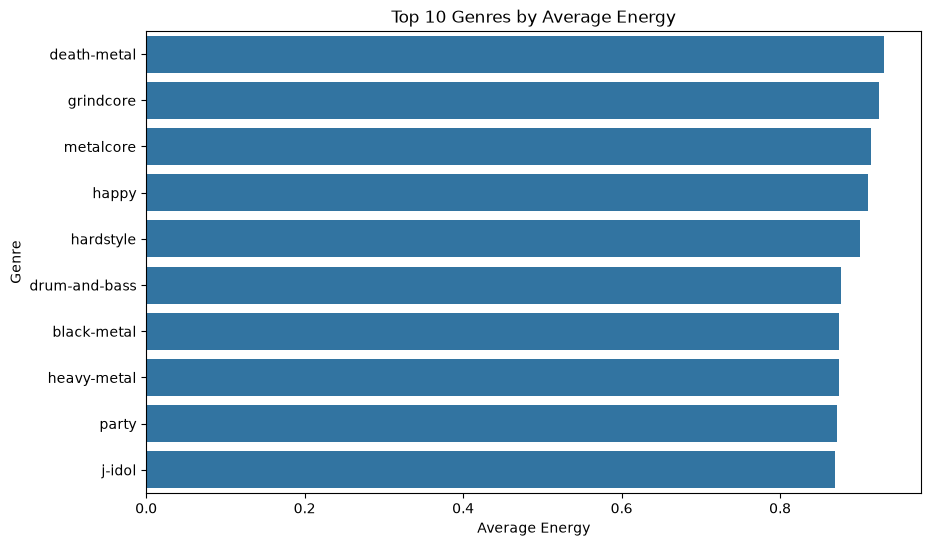

In [44]:
top_energy_genres = (
    df.groupby("track_genre")["energy"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_energy_genres.values,
    y=top_energy_genres.index
)

plt.title("Top 10 Genres by Average Energy")
plt.xlabel("Average Energy")
plt.ylabel("Genre")

plt.show()

In [45]:
bottom_energy_genres = (
    df.groupby("track_genre")["energy"]
    .mean()
    .sort_values(ascending=True)
    .head(10)
)

bottom_energy_genres

track_genre
classical    0.189827
new-age      0.214501
ambient      0.237162
romance      0.294304
disney       0.302519
opera        0.317054
piano        0.320103
guitar       0.324999
sleep        0.342072
jazz         0.352954
Name: energy, dtype: float64

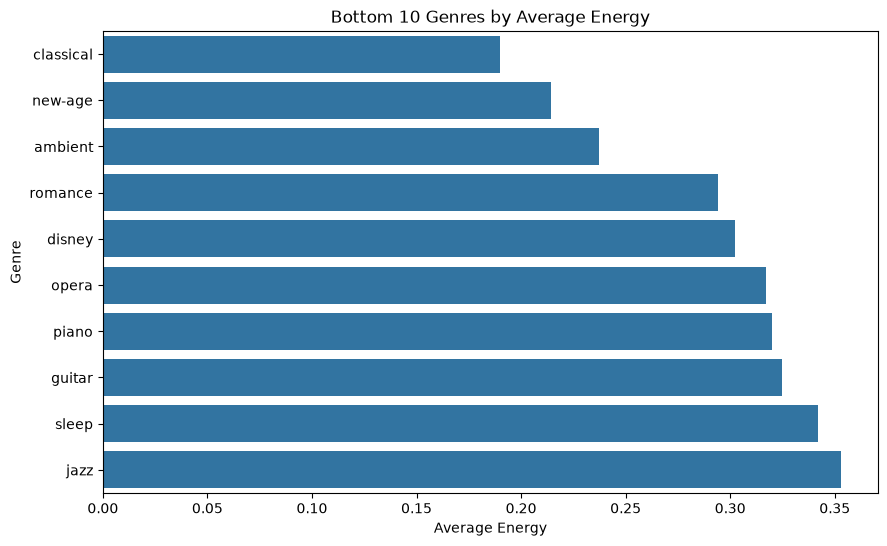

In [46]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=bottom_energy_genres.values,
    y=bottom_energy_genres.index
)

plt.title("Bottom 10 Genres by Average Energy")
plt.xlabel("Average Energy")
plt.ylabel("Genre")

plt.show()


## 4. Danceability by genre

The highest five genre averages are Kids (0.779), Chicago-house (0.766), Reggaeton (0.759), Latino (0.757), and Reggae (0.745). The lowest five are Sleep (0.168), Grindcore (0.272), Black metal (0.296), Iranian (0.301), and Opera (0.314).

**Observation:** Grindcore and black metal are among the highest-energy genres but among the lowest in danceability; death metal also has low average danceability despite its high average energy.

**Hypothesis for future analysis:** energy and danceability may not move together across tracks. These genre averages suggest a question to test, but do not measure a track-level relationship.

In [47]:
top_danceability_genres = (
    df.groupby("track_genre")["danceability"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

top_danceability_genres

track_genre
kids              0.778906
chicago-house     0.766176
reggaeton         0.758521
latino            0.757057
reggae            0.745331
hip-hop           0.736154
dancehall         0.734169
minimal-techno    0.729395
detroit-techno    0.722568
latin             0.721902
Name: danceability, dtype: float64

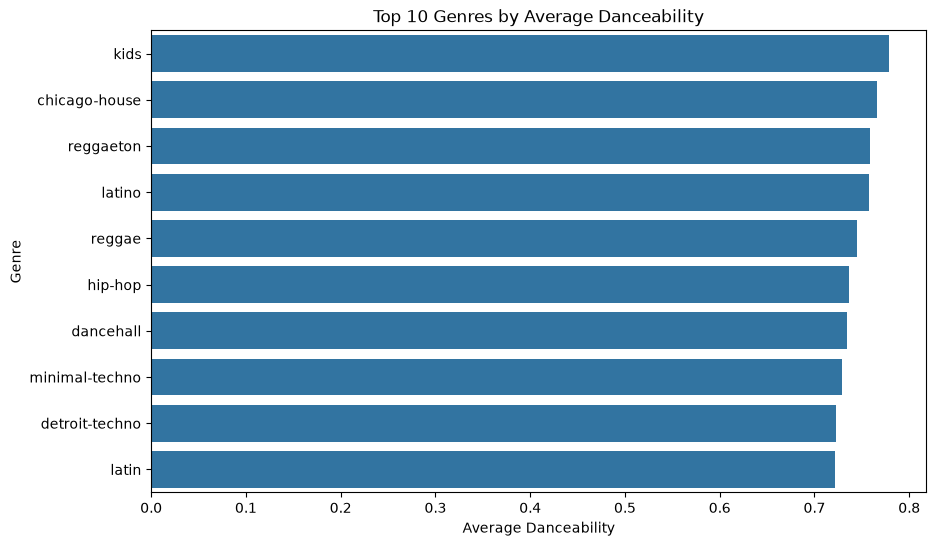

In [48]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_danceability_genres.values,
    y=top_danceability_genres.index
)

plt.title("Top 10 Genres by Average Danceability")
plt.xlabel("Average Danceability")
plt.ylabel("Genre")

plt.show()

In [49]:
bottom_danceability_genres = (
    df.groupby("track_genre")["danceability"]
    .mean()
    .sort_values(ascending=True)
    .head(10)
)

bottom_danceability_genres

track_genre
sleep          0.167923
grindcore      0.271854
black-metal    0.296411
iranian        0.300686
opera          0.313563
new-age        0.348455
ambient        0.367867
death-metal    0.368411
classical      0.381923
world-music    0.414572
Name: danceability, dtype: float64

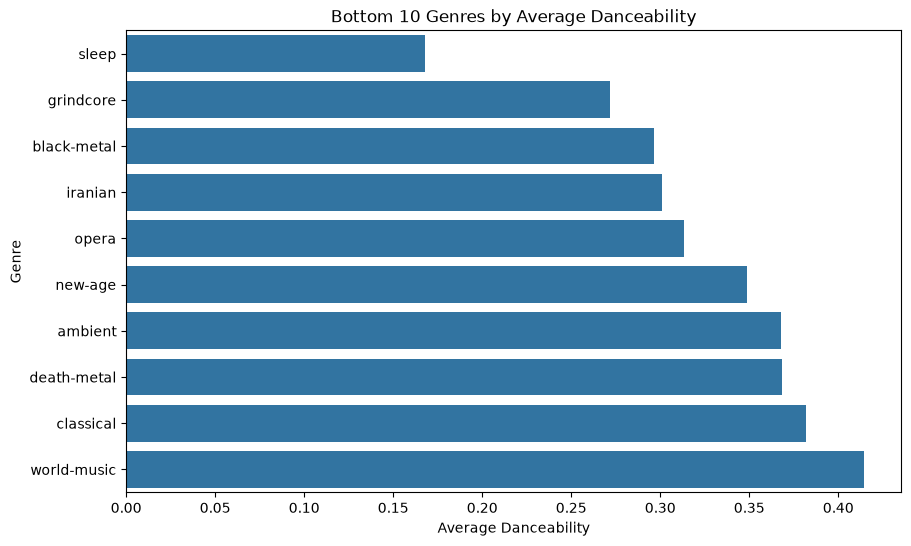

In [50]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=bottom_danceability_genres.values,
    y=bottom_danceability_genres.index
)

plt.title("Bottom 10 Genres by Average Danceability")
plt.xlabel("Average Danceability")
plt.ylabel("Genre")

plt.show()

## 5. Acousticness by genre

The highest five genre averages are Classical (0.920), Romance (0.869), Tango (0.846), New-age (0.824), and Opera (0.795). The lowest five are Death metal (0.007), Grindcore (0.009), Metalcore (0.010), Heavy metal (0.015), and Drum and bass (0.026). Classical, new-age, and ambient are among the more acoustic genres, while several metal and electronic genres have very low average acousticness.

In [51]:
top_acousticness_genres = (
    df.groupby("track_genre")["acousticness"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

top_acousticness_genres

track_genre
classical    0.920049
romance      0.869495
tango        0.846209
new-age      0.824022
opera        0.794931
ambient      0.776790
guitar       0.773053
disney       0.742892
comedy       0.726476
jazz         0.715816
Name: acousticness, dtype: float64

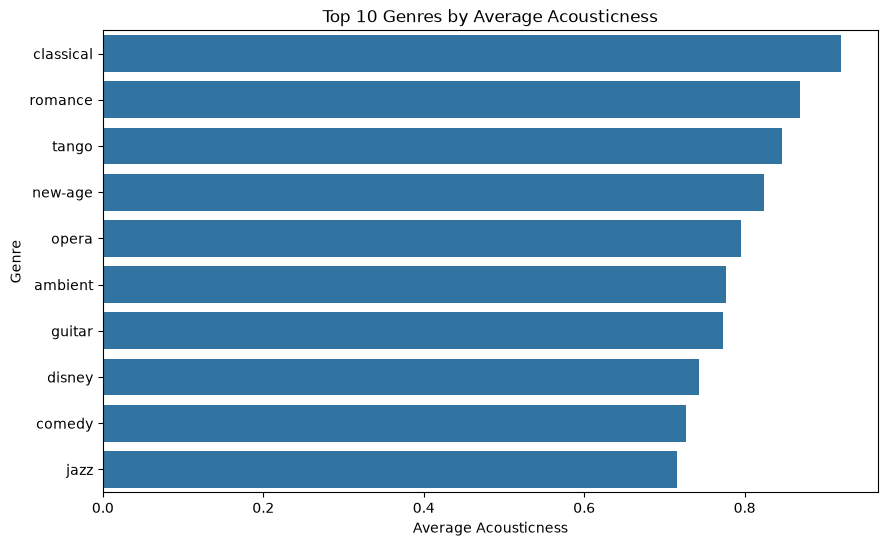

In [52]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_acousticness_genres.values,
    y=top_acousticness_genres.index
)

plt.title("Top 10 Genres by Average Acousticness")
plt.xlabel("Average Acousticness")
plt.ylabel("Genre")

plt.show()

In [53]:
bottom_acousticness_genres = (
    df.groupby("track_genre")["acousticness"]
    .mean()
    .sort_values(ascending=True)
    .head(10)
)

bottom_acousticness_genres

track_genre
death-metal      0.006696
grindcore        0.008698
metalcore        0.010286
heavy-metal      0.014968
drum-and-bass    0.025931
black-metal      0.027056
breakbeat        0.031410
chicago-house    0.035310
trance           0.035870
industrial       0.036728
Name: acousticness, dtype: float64

## Summary and next steps

The results above are descriptive genre averages and dataset counts; they do not show that a feature causes popularity or characterize every track in a genre. The dataset has not been fully cleaned. Valence and further relationship analysis (including popularity versus audio features) remain outstanding, as does a comparison of explicit and non-explicit tracks.